# Diabetes Risk Prediction

**Midterm project - Machine Learning Zoomcamp 2026**

Author: Alvaro Andres Salazar Valdez

This notebook builds a binary classification model that estimates whether a patient is at risk of diabetes, using routine clinical measurements (glucose, blood pressure, BMI, age, etc.). The final model is exported to `train.py` and served through a Flask API (`predict.py`) inside a Docker container.

## 1. Problem statement

Diabetes is a chronic disease that affects hundreds of millions of people. Many cases are diagnosed late because early symptoms are easy to ignore. A model that flags high-risk patients from cheap clinical measurements can help clinics prioritize who should take a confirmatory blood test.

**Goal:** predict `Outcome` (1 = diabetes, 0 = no diabetes) from 8 clinical features.

**How the result is used:** a doctor enters the patient's measurements in a web form and receives a risk probability. It is a *screening* tool, not a diagnosis.

## 2. Setup

In [1]:
import json
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report,
                             confusion_matrix, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="viridis")
pd.set_option("display.max_columns", None)

RANDOM_STATE = 42
DATA_PATH = Path("data/diabetes.csv")
MODEL_DIR = Path("model")
MODEL_DIR.mkdir(exist_ok=True)

print("Libraries loaded")

Libraries loaded


## 3. Load the dataset

The **Pima Indians Diabetes** dataset comes from the National Institute of Diabetes and Digestive and Kidney Diseases. It contains 768 female patients of Pima Indian heritage, at least 21 years old.

In [2]:
df = pd.read_csv(DATA_PATH)
print(f"Shape: {df.shape}")
df.head()

Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.85,3.37,0.00,1.00,3.00,6.00,17.00
Glucose,768.0,120.89,31.97,0.00,99.00,117.00,140.25,199.00
BloodPressure,768.0,69.11,19.36,0.00,62.00,72.00,80.00,122.00
SkinThickness,768.0,20.54,15.95,0.00,0.00,23.00,32.00,99.00
Insulin,768.0,79.80,115.24,0.00,0.00,30.50,127.25,846.00
BMI,768.0,31.99,7.88,0.00,27.30,32.00,36.60,67.10
DiabetesPedigreeFunction,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
Age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00
Outcome,768.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00


## 4. Exploratory Data Analysis (EDA)

### 4.1 Target variable

The classes are imbalanced: about 35% of patients have diabetes. This matters later when choosing the metric (accuracy alone can be misleading).

Outcome
0    500
1    268
Name: count, dtype: int64
Positive rate: 34.90%


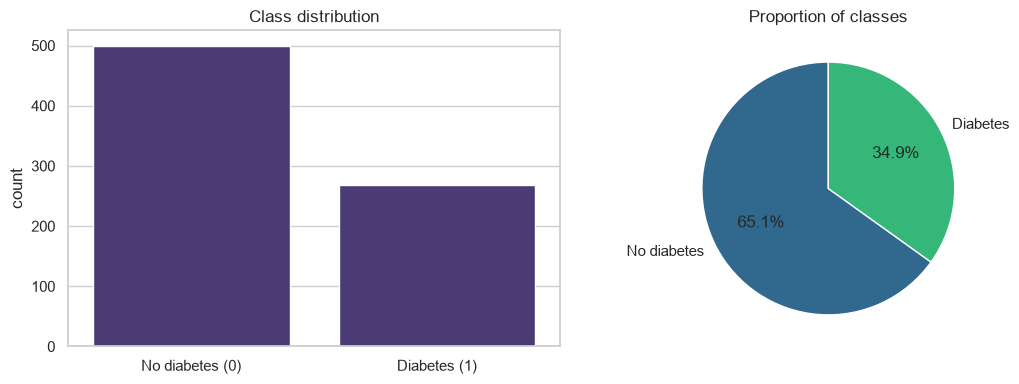

In [5]:
counts = df["Outcome"].value_counts().sort_index()
print(counts)
print(f"Positive rate: {df['Outcome'].mean():.2%}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x="Outcome", data=df, ax=axes[0])
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["No diabetes (0)", "Diabetes (1)"])
axes[0].set_title("Class distribution")
axes[0].set_xlabel("")

axes[1].pie(counts, labels=["No diabetes", "Diabetes"], autopct="%1.1f%%",
            colors=sns.color_palette("viridis", 2), startangle=90)
axes[1].set_title("Proportion of classes")
plt.tight_layout()
plt.show()

### 4.2 Missing values hidden as zeros

There are no `NaN` values, but several columns contain **zeros that are biologically impossible** (a living person cannot have 0 glucose, 0 blood pressure or 0 BMI). In this dataset a zero means *"not measured"*, so we must treat those zeros as missing data.

In [6]:
zero_as_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
zero_counts = (df[zero_as_missing] == 0).sum().sort_values(ascending=False)

missing_table = pd.DataFrame({
    "zeros (treated as missing)": zero_counts,
    "percentage": (zero_counts / len(df) * 100).round(1),
})
missing_table["percentage"] = missing_table["percentage"].astype(str) + " %"
missing_table

,zeros (treated as missing),percentage
Insulin,374,48.7 %
SkinThickness,227,29.6 %
BloodPressure,35,4.6 %
BMI,11,1.4 %
Glucose,5,0.7 %


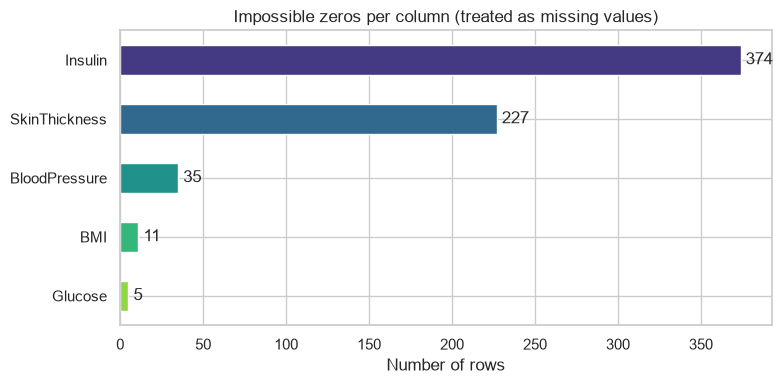

In [7]:
ax = zero_counts.plot(kind="barh", figsize=(8, 4), color=sns.color_palette("viridis", len(zero_counts)))
ax.set_title("Impossible zeros per column (treated as missing values)")
ax.set_xlabel("Number of rows")
ax.invert_yaxis()
for i, value in enumerate(zero_counts.values):
    ax.text(value + 3, i, str(value), va="center")
plt.tight_layout()
plt.show()

### 4.3 Distribution of the features

The histograms below show the shape of every feature. `Glucose`, `BMI` and `Age` already look different between the two classes, which is a good sign for the model.

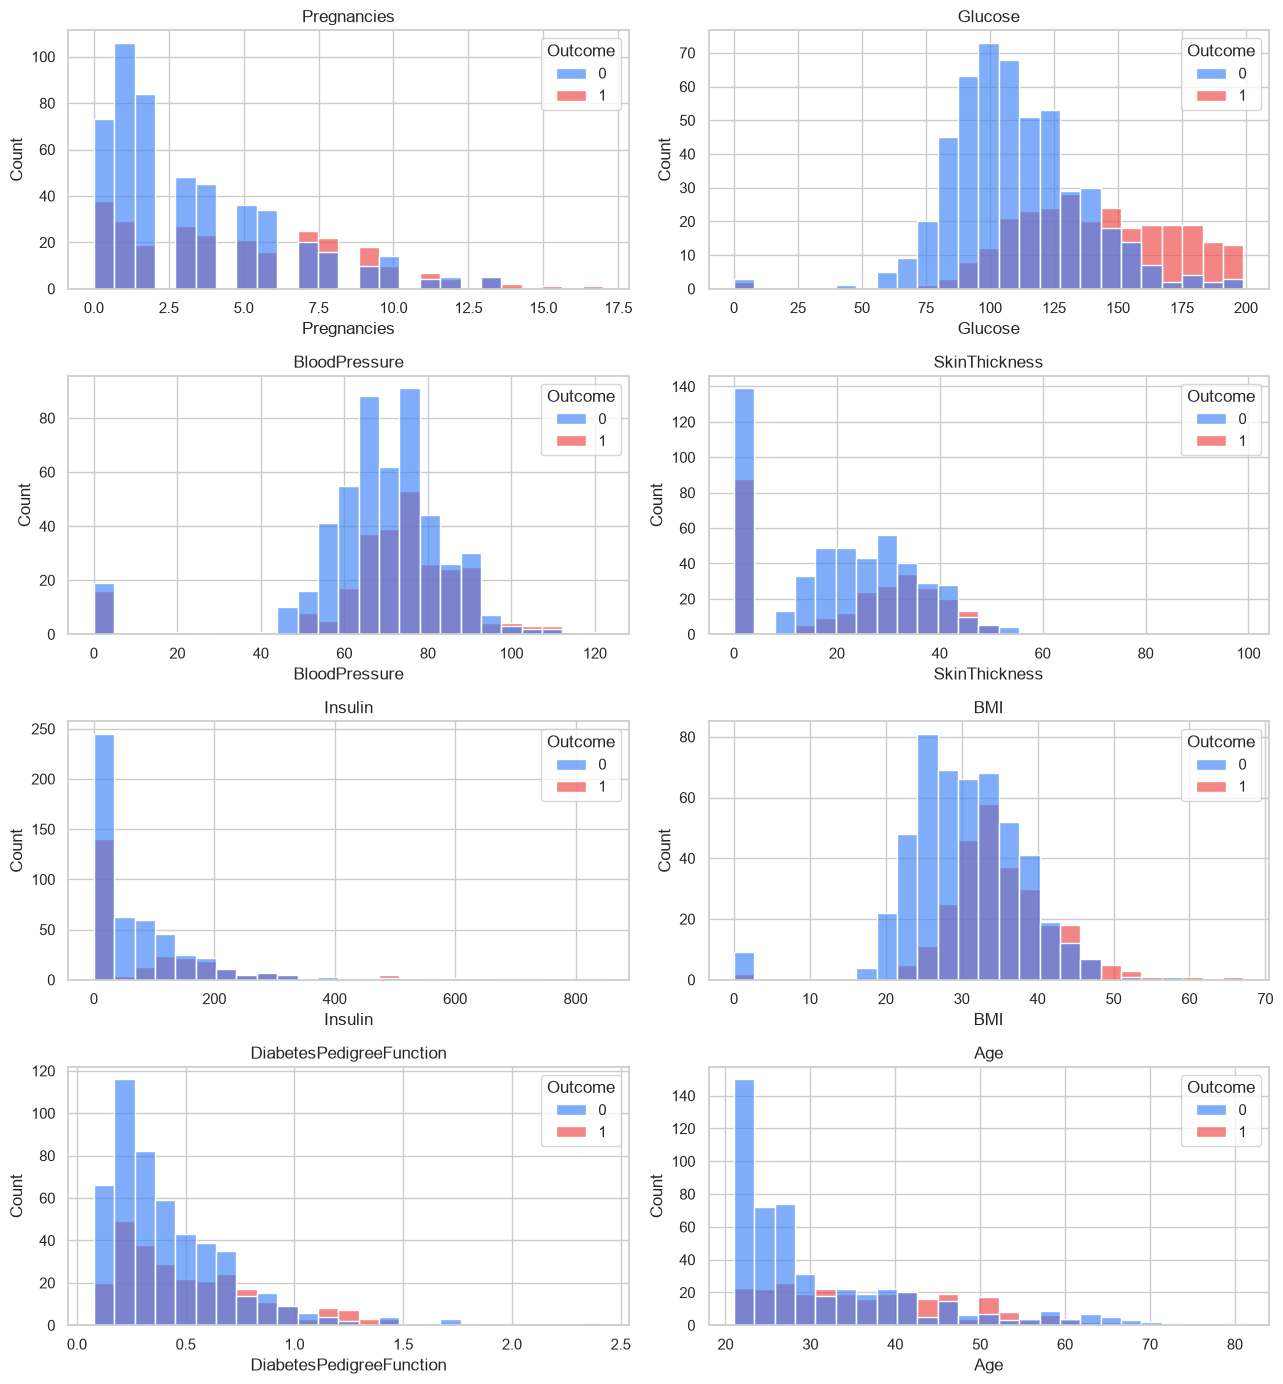

In [8]:
features = [c for c in df.columns if c != "Outcome"]

fig, axes = plt.subplots(4, 2, figsize=(13, 14))
for ax, column in zip(axes.ravel(), features):
    sns.histplot(data=df, x=column, hue="Outcome", bins=25,
                 palette={0: "#3b82f6", 1: "#ef4444"}, alpha=0.65, ax=ax)
    ax.set_title(column)
plt.tight_layout()
plt.show()

### 4.4 Relationship with the target

Boxplots make the separation between classes easier to see. Glucose and BMI are the features that separate the two groups the most.

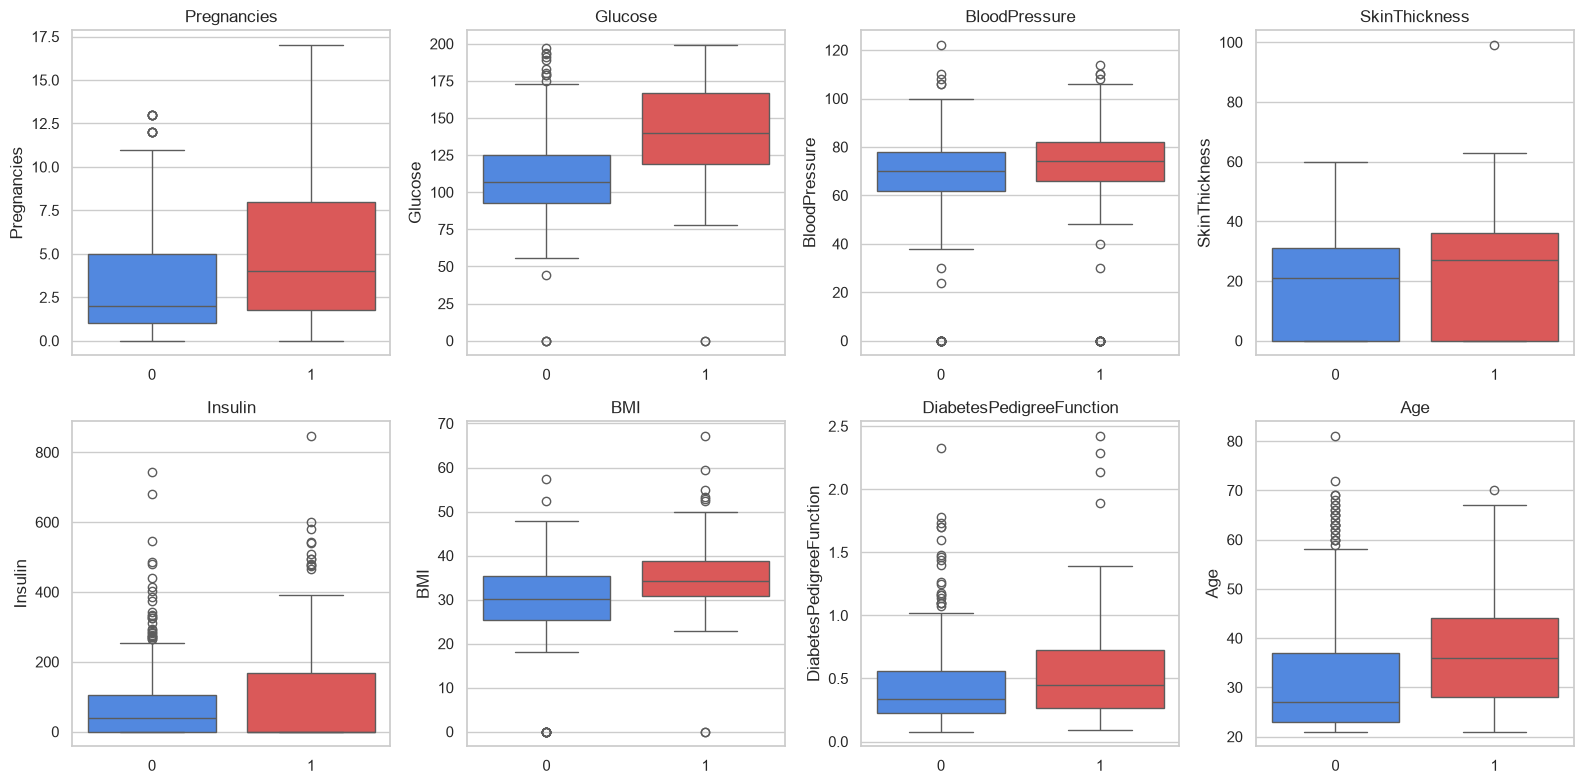

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, column in zip(axes.ravel(), features):
    sns.boxplot(data=df, x="Outcome", y=column, hue="Outcome",
                palette=["#3b82f6", "#ef4444"], legend=False, ax=ax)
    ax.set_title(column)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

### 4.5 Correlation analysis

`Glucose` is the feature most correlated with diabetes, followed by `BMI` and `Age`. `SkinThickness` and `Insulin` are strongly correlated with each other, which makes sense because both measure related metabolic signals.

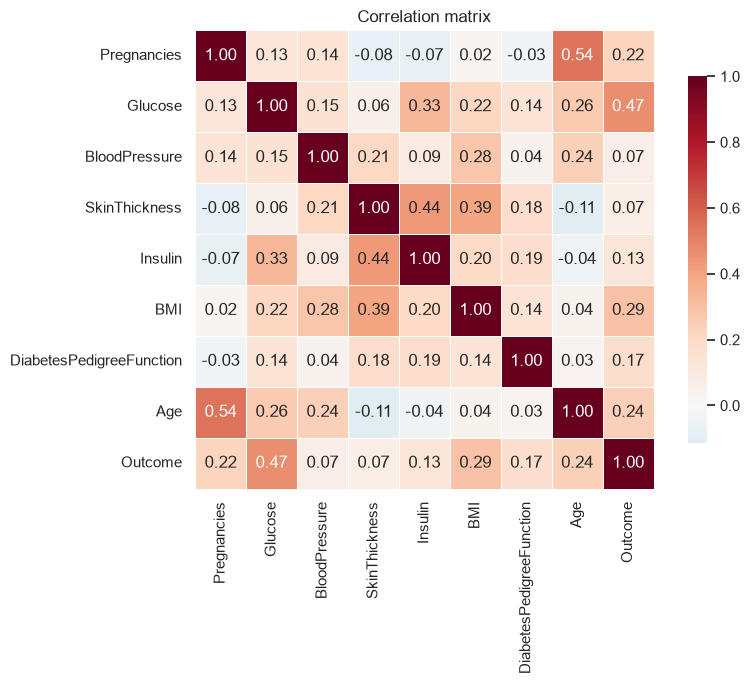

In [10]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

In [11]:
corr["Outcome"].drop("Outcome").sort_values(ascending=False).round(3)

Glucose                     0.467
BMI                         0.293
Age                         0.238
Pregnancies                 0.222
DiabetesPedigreeFunction    0.174
Insulin                     0.131
SkinThickness               0.075
BloodPressure               0.065
Name: Outcome, dtype: float64

### 4.6 Key EDA findings

1. **No explicit missing values**, but 5 columns contain impossible zeros that must be imputed (up to 49% of `Insulin`).
2. **Moderate class imbalance** (65% / 35%). We will use `ROC AUC` and `recall` instead of accuracy alone.
3. **Glucose, BMI, Age and Pregnancies** are the features most correlated with the target.
4. Feature scales are very different (insulin goes up to ~850, pedigree function below 2.5), so scaling is required for the linear model.

## 5. Data cleaning and train/test split

Following the finding above, zeros are replaced by `NaN` and will be imputed with the **median of the training set** inside the model pipeline (this avoids data leakage).

We keep 20% of the data as a final test set that the model never sees during training.

In [12]:
df_clean = df.copy()
df_clean[zero_as_missing] = df_clean[zero_as_missing].replace(0, np.nan)

print("Missing values after replacing zeros:")
print(df_clean[zero_as_missing].isna().sum())

X = df_clean[features]
y = df_clean["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(f"\nTrain: {X_train.shape} | Test: {X_test.shape}")
print(f"Positive rate train: {y_train.mean():.2%} | test: {y_test.mean():.2%}")

Missing values after replacing zeros:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Train: (614, 8) | Test: (154, 8)
Positive rate train: 34.85% | test: 35.06%


## 6. Preprocessing pipeline

Every candidate model uses the same pipeline:

1. **Median imputation** for the missing values.
2. **Standard scaling** so that all features have mean 0 and standard deviation 1.

Using a `Pipeline` guarantees that the imputer and scaler are fitted only on training data, and it lets us save the whole object in a single file.

In [13]:
def build_pipeline(estimator):
    return Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", estimator),
    ])

build_pipeline(LogisticRegression())

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto accou

## 7. Model comparison with cross-validation

We compare three models with 5-fold stratified cross-validation, using **ROC AUC** as the scoring metric:

* **Logistic Regression** - linear baseline, easy to interpret.
* **Random Forest** - non-linear, robust to outliers.
* **Gradient Boosting** - non-linear, usually very strong on tabular data.

In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

candidates = {
    "Logistic Regression": build_pipeline(
        LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    "Random Forest": build_pipeline(
        RandomForestClassifier(random_state=RANDOM_STATE)),
    "Gradient Boosting": build_pipeline(
        GradientBoostingClassifier(random_state=RANDOM_STATE)),
}

cv_scores = {}
for name, model in candidates.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    cv_scores[name] = scores
    print(f"{name:20s} ROC AUC = {scores.mean():.4f} +/- {scores.std():.4f}")

Logistic Regression  ROC AUC = 0.8434 +/- 0.0185


Random Forest        ROC AUC = 0.8154 +/- 0.0230


Gradient Boosting    ROC AUC = 0.8206 +/- 0.0155


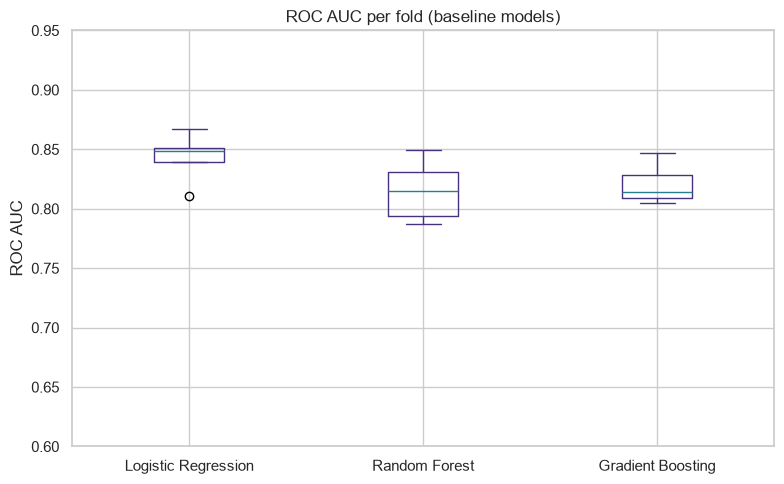

In [15]:
pd.DataFrame(cv_scores).plot(kind="box", figsize=(8, 5), title="ROC AUC per fold (baseline models)")
plt.ylabel("ROC AUC")
plt.ylim(0.6, 0.95)
plt.tight_layout()
plt.show()

## 8. Hyperparameter tuning

Now we tune each model with `GridSearchCV` (5 folds, ROC AUC). We also try `class_weight="balanced"` for the two models that support it, because the classes are imbalanced and missing a sick patient (false negative) is more costly than a false alarm.

In [16]:
param_grids = {
    "Logistic Regression": {
        "classifier__C": [0.01, 0.1, 1.0, 10.0],
        "classifier__class_weight": [None, "balanced"],
    },
    "Random Forest": {
        "classifier__n_estimators": [200, 400],
        "classifier__max_depth": [None, 4, 8],
        "classifier__min_samples_leaf": [1, 3],
        "classifier__class_weight": [None, "balanced"],
    },
    "Gradient Boosting": {
        "classifier__n_estimators": [100, 200],
        "classifier__learning_rate": [0.05, 0.1],
        "classifier__max_depth": [2, 3],
    },
}

searches = {}
for name, model in candidates.items():
    print(f"Tuning {name}...")
    search = GridSearchCV(model, param_grids[name], cv=cv, scoring="roc_auc", n_jobs=-1, refit=True)
    search.fit(X_train, y_train)
    searches[name] = search
    print(f"  best CV ROC AUC: {search.best_score_:.4f}")
    print(f"  best params: {search.best_params_}")

Tuning Logistic Regression...
  best CV ROC AUC: 0.8450
  best params: {'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}
Tuning Random Forest...


  best CV ROC AUC: 0.8389
  best params: {'classifier__class_weight': None, 'classifier__max_depth': 4, 'classifier__min_samples_leaf': 3, 'classifier__n_estimators': 400}
Tuning Gradient Boosting...


  best CV ROC AUC: 0.8297
  best params: {'classifier__learning_rate': 0.05, 'classifier__max_depth': 2, 'classifier__n_estimators': 100}


## 9. Final evaluation on the test set

The test set was never used for training or tuning. We take the model with the best cross-validation score and evaluate it once on the test set.

In [17]:
best_name = max(searches, key=lambda name: searches[name].best_score_)
best_model = searches[best_name].best_estimator_
print(f"Best model: {best_name} (CV ROC AUC = {searches[best_name].best_score_:.4f})")

y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["No diabetes", "Diabetes"], digits=4))
print(f"ROC AUC on the test set: {roc_auc_score(y_test, y_proba):.4f}")

Best model: Logistic Regression (CV ROC AUC = 0.8450)

Classification report:
              precision    recall  f1-score   support

 No diabetes     0.8022    0.7300    0.7644       100
    Diabetes     0.5714    0.6667    0.6154        54

    accuracy                         0.7078       154
   macro avg     0.6868    0.6983    0.6899       154
weighted avg     0.7213    0.7078    0.7121       154

ROC AUC on the test set: 0.8104


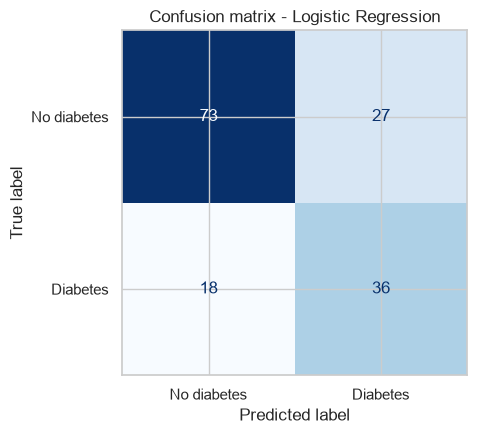

In [18]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["No diabetes", "Diabetes"],
    cmap="Blues", colorbar=False, ax=ax)
ax.set_title(f"Confusion matrix - {best_name}")
plt.tight_layout()
plt.show()

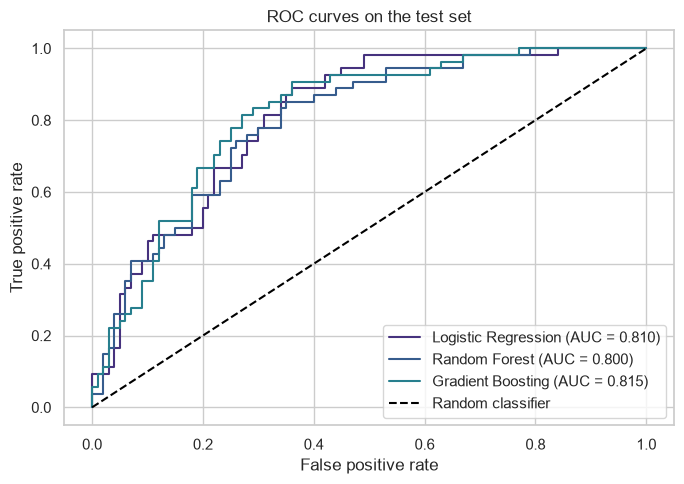

In [19]:
plt.figure(figsize=(7, 5))
for name, search in searches.items():
    proba = search.best_estimator_.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves on the test set")
plt.legend()
plt.tight_layout()
plt.show()

## 10. Feature importance and interpretation

Because the selected model is a logistic regression, its coefficients tell us the direction of each effect on the log-odds of diabetes (the features were scaled, so the magnitudes are comparable).

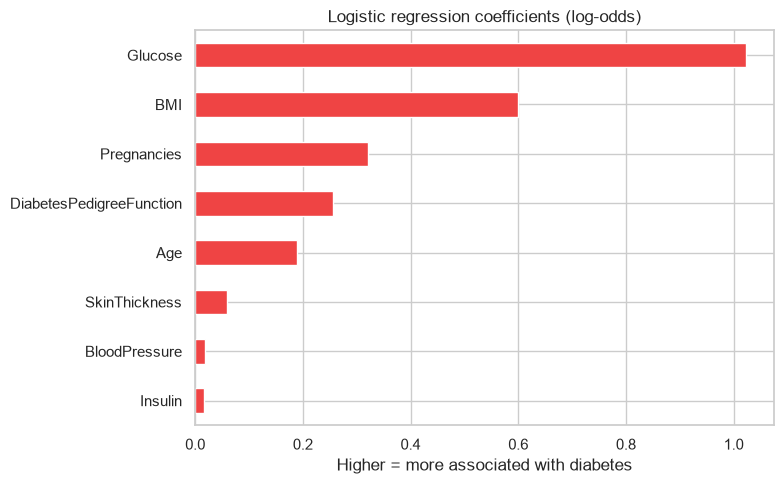

Glucose                     1.024
BMI                         0.599
Pregnancies                 0.321
DiabetesPedigreeFunction    0.256
Age                         0.189
SkinThickness               0.059
BloodPressure               0.017
Insulin                     0.016
dtype: float64

In [20]:
classifier = best_model.named_steps["classifier"]

if hasattr(classifier, "coef_"):
    importance = pd.Series(classifier.coef_[0], index=features).sort_values()
    title = "Logistic regression coefficients (log-odds)"
else:
    importance = pd.Series(classifier.feature_importances_, index=features).sort_values()
    title = "Feature importance"

plt.figure(figsize=(8, 5))
colors = ["#ef4444" if value > 0 else "#3b82f6" for value in importance.values]
importance.plot(kind="barh", color=colors)
plt.title(title)
plt.xlabel("Higher = more associated with diabetes")
plt.tight_layout()
plt.show()

importance.sort_values(ascending=False).round(3)

**Interpretation:** higher glucose, BMI, age and number of pregnancies increase the estimated risk, while a higher diabetes pedigree function has a smaller effect once the other variables are taken into account. This matches the medical literature and the EDA above.

## 11. Save the final model

We save the **whole pipeline** (imputer + scaler + classifier) together with the feature list and the test metrics, so the Flask API can load one file and predict directly from raw values.

In [21]:
bundle = {
    "model": best_model,
    "model_name": best_name,
    "features": features,
    "target": "Outcome",
    "threshold": 0.5,
    "test_metrics": {
        "accuracy": round(float((y_pred == y_test).mean()), 4),
        "roc_auc": round(float(roc_auc_score(y_test, y_proba)), 4),
        "confusion_matrix": confusion_matrix(y_test, y_pred).tolist(),
    },
}

model_path = MODEL_DIR / "diabetes_pipeline.joblib"
joblib.dump(bundle, model_path)
print(f"Saved to {model_path} ({model_path.stat().st_size / 1024:.1f} KB)")

loaded = joblib.load(model_path)
sample = X_test.iloc[[0]]
print("Reloaded model prediction:", loaded["model"].predict_proba(sample)[0, 1].round(4))
print("Actual label:", int(y_test.iloc[0]))

Saved to model\diabetes_pipeline.joblib (2.5 KB)
Reloaded model prediction: 0.7003
Actual label: 0


## 12. Conclusions

* The dataset needed a careful cleaning step: **zeros were not real measurements** but missing values.
* Three models were compared with cross-validation and all of them were tuned with `GridSearchCV`.
* The **Logistic Regression** with `class_weight="balanced"` obtained the best cross-validation ROC AUC (~0.845) and a test ROC AUC of ~0.81, which is a solid result for this small dataset.
* Scaling and median imputation are part of the saved pipeline, so the API accepts raw clinical values (a zero means "not measured").
* The model is exported to `train.py`, served by `predict.py` (Flask) and containerized with Docker. Deployment instructions are in the README.

**Limitations:** the dataset is small (768 rows) and only includes women of Pima Indian heritage, so the model should not be used on other populations without retraining. It is a screening aid, not a medical diagnosis.